In [4]:
import sys
sys.path.insert(0, '/home/nvidia/24BCE1793/fignn_cni__project')  # on A100

from src.preprocessing.preprocess import process_file
from src.preprocessing.plv import batch_compute_plv
from src.preprocessing.graph_builder import build_graph_dataset

from src.models.model import FIGNNEncoder, count_parameters
from torch_geometric.loader import DataLoader
import torch

/home/nvidia/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/home/nvidia/.venv/lib/python3.12/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: /home/nvidia/.venv/lib/python3.12/site-packages/torch_scatter/_version_cuda.so: undefined symbol: _ZN5torch3jit17parseSchemaOrNameERKSsb
  import torch_geometric.typing
/home/nvidia/.venv/lib/python3.12/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-sparse'. Disabling its usage. Stacktrace: /home/nvidia/.venv/lib/python3.12/site-packages/torch_sparse/_version_cuda.so: undefined symbol: _ZN5torch3jit17parseSchemaOrNameERKSsb
  import torch_geom

In [5]:
print(os.getcwd())

/home/nvidia/24BCE1793/fignn_cni__project/notebooks


In [4]:
result = process_file(
    "lp-dev/24BCE1793/data/raw/sub-01/ses-S1/eeg/zeroBACK.set",
    label=0
)
print(f"Epochs:   {result['n_epochs']}")
print(f"Channels: {result['n_channels']}")
print(f"Theta shape: {result['band_epochs']['theta'].shape}")

  Loading: zeroBACK.set  label=0


d:\Portfolio Projects\QML EEG Paper\stage-1 implementation\notebooks\..\src\preprocessing\preprocess.py:37: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
d:\Portfolio Projects\QML EEG Paper\stage-1 implementation\notebooks\..\src\preprocessing\preprocess.py:37: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
d:\Portfolio Projects\QML EEG Paper\stage-1 implementation\notebooks\..\src\preprocessing\preprocess.py:37: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(set_path, prel

    → 62 channels  |  198 epochs  |  500.0 Hz
Epochs:   198
Channels: 62
Theta shape: (198, 62, 1000)


In [5]:
# Slice just 3 epochs to test PLV fast
test_bands = {band: result['band_epochs'][band][:3] 
              for band in result['band_epochs']}
test_result = {**result, 'band_epochs': test_bands, 'n_epochs': 3}

plv_list = batch_compute_plv(test_result['band_epochs'])
print(f"PLV list length: {len(plv_list)}")
print(f"PLV matrix shape (delta): {plv_list[0]['delta'].shape}")

    PLV: epoch 0/3
PLV list length: 3
PLV matrix shape (delta): (62, 62)


In [6]:
graphs = build_graph_dataset(test_result, plv_list)
g = graphs[0]
print(f"Nodes: {g.x.shape}")
print(f"Edges: {g.edge_index.shape}")
print(f"Edge features: {g.edge_attr.shape}")
print(f"Label: {g.y}")

    Built 3 graphs  |  sample edges: 2422  |  label: 0
Nodes: torch.Size([62, 4])
Edges: torch.Size([2, 2422])
Edge features: torch.Size([2422, 4])
Label: tensor([0])


In [9]:
model = FIGNNEncoder()
count_parameters(model)

# Make a small batch from your 3 test graphs
loader = DataLoader(graphs, batch_size=3)
batch  = next(iter(loader))

# Forward pass — no training, just checking shapes
model.eval()
with torch.no_grad():
    z = model(batch)

print(f"Output z shape: {z.shape}")
print(f"Expected: torch.Size([3, 32])")

Trainable parameters: 12,100
Output z shape: torch.Size([3, 32])
Expected: torch.Size([3, 32])


In [ ]:
import mne
mne.set_log_level("WARNING")
raw_tmp = mne.io.read_raw_eeglab(
    "../data/raw/sub-01/ses-S1/eeg/zeroBACK.set", 
    preload=False, verbose=False
)
ecg_chs = [ch for ch in raw_tmp.ch_names if "ECG" in ch.upper()]
raw_tmp.drop_channels(ecg_chs)
ch_names = raw_tmp.ch_names  # exactly 62 names

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import networkx as nx
from torch_geometric.utils import to_networkx
import numpy as np

g = graphs[0]

# Convert to networkx
G = to_networkx(g, to_undirected=True)

# Node positions — use actual electrode layout (approximate)
# For now just use spring layout
pos = nx.spring_layout(G, seed=42)

# Node colours = theta band power (index 1)
node_colors = g.x[:, 1].numpy()  # theta power per electrode

# Edge weights = mean PLV across 4 bands
edge_weights = g.edge_attr.mean(dim=1).numpy()

fig, ax = plt.subplots(figsize=(10, 8))
ax.set_facecolor("#0d0d1a")
fig.patch.set_facecolor("#0d0d1a")

# Draw edges
nx.draw_networkx_edges(G, pos, ax=ax,
    edge_color=edge_weights[:len(G.edges())],
    edge_cmap=plt.cm.plasma,
    alpha=0.3, width=0.5)

# Draw nodes
nc = nx.draw_networkx_nodes(G, pos, ax=ax,
    node_color=node_colors,
    cmap=plt.cm.RdYlGn,
    node_size=120)

# Labels
nx.draw_networkx_labels(G, pos, ax=ax,
    labels={i: ch_names[i] for i in range(len(ch_names))},
    font_size=5, font_color="white")

plt.colorbar(nc, ax=ax, label="Theta power", shrink=0.6)
ax.set_title("EEG Functional Connectivity Graph — zeroBACK epoch 0", 
             color="white", fontsize=11)
ax.axis("off")

plt.tight_layout()
plt.savefig("outputs/plots/graph_viz.png", dpi=150, bbox_inches="tight")
plt.close()
print("Saved to outputs/plots/graph_viz.png")

KeyError: 62

In [22]:
import mne
import os
import numpy as np

BASE = "/lp-dev/24BCE1793/data/raw/sub-01/ses-S1/eeg"

files = {
    "zeroBACK": os.path.join(BASE, "zeroBACK.set"),
    "oneBACK":  os.path.join(BASE, "oneBACK.set"),
    "twoBACK":  os.path.join(BASE, "twoBACK.set"),
}

raws = {}

for condition, path in files.items():
    print("\n" + "=" * 60)
    print(condition, path)

    raw = mne.io.read_raw_eeglab(
        path,
        preload=True,
        verbose=False
    )

    print("Channels:", len(raw.ch_names))
    print("Duration:", raw.times[-1], "s")
    print("Sampling:", raw.info["sfreq"], "Hz")

    raws[condition] = raw


zeroBACK /lp-dev/24BCE1793/data/raw/sub-01/ses-S1/eeg/zeroBACK.set


/tmp/ipykernel_3627592/4266102280.py:19: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(
/tmp/ipykernel_3627592/4266102280.py:19: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(
/tmp/ipykernel_3627592/4266102280.py:19: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(


Channels: 63
Duration: 396.574 s
Sampling: 500.0 Hz

oneBACK /lp-dev/24BCE1793/data/raw/sub-01/ses-S1/eeg/oneBACK.set


/tmp/ipykernel_3627592/4266102280.py:19: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(
/tmp/ipykernel_3627592/4266102280.py:19: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(
/tmp/ipykernel_3627592/4266102280.py:19: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(


Channels: 63
Duration: 411.314 s
Sampling: 500.0 Hz

twoBACK /lp-dev/24BCE1793/data/raw/sub-01/ses-S1/eeg/twoBACK.set
Channels: 63
Duration: 394.808 s
Sampling: 500.0 Hz


/tmp/ipykernel_3627592/4266102280.py:19: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(
/tmp/ipykernel_3627592/4266102280.py:19: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(
/tmp/ipykernel_3627592/4266102280.py:19: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(


In [23]:
for condition, raw in raws.items():

    print("\n" + "=" * 60)
    print(condition)

    print("\nANNOTATION DESCRIPTIONS:")
    descriptions, counts = np.unique(
        raw.annotations.description,
        return_counts=True
    )

    for d, c in zip(descriptions, counts):
        print(f"{d:20s} : {c}")

    events, event_id = mne.events_from_annotations(
        raw,
        verbose=False
    )

    print("\nEVENT_ID:")
    for name, eid in event_id.items():
        print(f"{name:20s} -> {eid}")

    print("\nTotal events:", len(events))
    print("First 20 events:")
    print(events[:20])


zeroBACK

ANNOTATION DESCRIPTIONS:
601                  : 1
6011                 : 6
6012                 : 3
6021                 : 96
6022                 : 48
6031                 : 1
6032                 : 47
boundary             : 1

EVENT_ID:
601                  -> 1
6011                 -> 2
6012                 -> 3
6021                 -> 4
6022                 -> 5
6031                 -> 6
6032                 -> 7
boundary             -> 8

Total events: 203
First 20 events:
[[    0     0     8]
 [ 3904     0     2]
 [ 5910     0     2]
 [ 6922     0     4]
 [ 8181     0     4]
 [ 9439     0     4]
 [10697     0     4]
 [11956     0     5]
 [12095     0     7]
 [13214     0     4]
 [14472     0     4]
 [15731     0     4]
 [16989     0     5]
 [17143     0     7]
 [18247     0     5]
 [18439     0     7]
 [19506     0     4]
 [20764     0     4]
 [22022     0     4]
 [23281     0     4]]

oneBACK

ANNOTATION DESCRIPTIONS:
611                  : 1
6111                 : 3


In [24]:
for condition, raw in raws.items():

    events, event_id = mne.events_from_annotations(
        raw,
        verbose=False
    )

    sfreq = raw.info["sfreq"]

    print("\n" + "=" * 60)
    print(condition)

    for name, eid in event_id.items():

        samples = events[events[:, 2] == eid, 0]

        if len(samples) < 2:
            continue

        intervals = np.diff(samples) / sfreq

        print(
            f"{name:20s} "
            f"n={len(samples):3d} | "
            f"median interval={np.median(intervals):.3f}s | "
            f"min={intervals.min():.3f}s | "
            f"max={intervals.max():.3f}s"
        )


zeroBACK
6011                 n=  6 | median interval=4.012s | min=4.010s | max=129.188s
6012                 n=  3 | median interval=130.493s | min=127.788s | max=133.198s
6021                 n= 96 | median interval=2.518s | min=2.516s | max=14.916s
6022                 n= 48 | median interval=5.034s | min=2.516s | max=25.166s
6032                 n= 47 | median interval=6.280s | min=2.032s | max=25.294s

oneBACK
6111                 n=  3 | median interval=129.336s | min=128.656s | max=130.016s
6112                 n=  3 | median interval=129.327s | min=128.658s | max=129.996s
6121                 n= 96 | median interval=2.518s | min=2.516s | max=12.890s
6122                 n= 48 | median interval=5.034s | min=2.516s | max=44.442s
6132                 n= 46 | median interval=5.070s | min=2.498s | max=44.144s

twoBACK
6211                 n=  3 | median interval=128.759s | min=128.144s | max=129.374s
6212                 n=  3 | median interval=128.747s | min=128.120s | max=129.374

In [4]:
import mne
mne.set_log_level('WARNING')

for task in ['zeroBACK', 'oneBACK', 'twoBACK']:
    path = f'/lp-dev/24BCE1793/data/raw/sub-01/ses-S1/eeg/{task}.set'
    raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
    events, event_id = mne.events_from_annotations(raw)
    
    if '6021' in event_id:
        epochs = mne.Epochs(raw, events,
                            event_id={'6021': event_id['6021']},
                            tmin=0.0, tmax=2.0,
                            baseline=None, preload=True, verbose=False)
        print(f"{task}: {len(epochs)} trials, shape {epochs.get_data().shape}")
    else:
        print(f"{task}: 6021 not found")

/tmp/ipykernel_627940/1985076682.py:6: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/1985076682.py:6: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/1985076682.py:6: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


zeroBACK: 96 trials, shape (96, 63, 1001)


/tmp/ipykernel_627940/1985076682.py:6: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/1985076682.py:6: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/1985076682.py:6: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


oneBACK: 6021 not found
twoBACK: 6021 not found


/tmp/ipykernel_627940/1985076682.py:6: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/1985076682.py:6: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/1985076682.py:6: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


In [5]:
for task in ['zeroBACK', 'oneBACK', 'twoBACK']:
    path = f'/lp-dev/24BCE1793/data/raw/sub-01/ses-S1/eeg/{task}.set'
    raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
    events, event_id = mne.events_from_annotations(raw)
    if '6021' in event_id:
        epochs = mne.Epochs(raw, events,
                            event_id={'6021': event_id['6021']},
                            tmin=0.0, tmax=2.0,
                            baseline=None, preload=True, verbose=False)
        print(f"{task}: {len(epochs)} trials")
    else:
        print(f"{task}: 6021 not found")

/tmp/ipykernel_627940/761208740.py:3: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/761208740.py:3: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/761208740.py:3: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


zeroBACK: 96 trials


/tmp/ipykernel_627940/761208740.py:3: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/761208740.py:3: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/761208740.py:3: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


oneBACK: 6021 not found
twoBACK: 6021 not found


/tmp/ipykernel_627940/761208740.py:3: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/761208740.py:3: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/761208740.py:3: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


In [3]:
import mne
import numpy as np

mne.set_log_level('WARNING')
path = '/lp-dev/24BCE1793/data/raw/sub-01/ses-S1/eeg/zeroBACK.set'
raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)

events, event_id = mne.events_from_annotations(raw)
print("Event ID map:", event_id)
print("\nAll events (sample, prev, code):")
for e in events:
    # find which annotation label this maps to
    for name, code in event_id.items():
        if e[2] == code:
            print(f"  t={e[0]/raw.info['sfreq']:.2f}s  code={name}  ({e[2]})")
            break

Event ID map: {'601': 1, '6011': 2, '6012': 3, '6021': 4, '6022': 5, '6031': 6, '6032': 7, 'boundary': 8}

All events (sample, prev, code):
  t=0.00s  code=boundary  (8)
  t=7.81s  code=6011  (2)
  t=11.82s  code=6011  (2)
  t=13.84s  code=6021  (4)
  t=16.36s  code=6021  (4)
  t=18.88s  code=6021  (4)
  t=21.39s  code=6021  (4)
  t=23.91s  code=6022  (5)
  t=24.19s  code=6032  (7)
  t=26.43s  code=6021  (4)
  t=28.94s  code=6021  (4)
  t=31.46s  code=6021  (4)
  t=33.98s  code=6022  (5)
  t=34.29s  code=6032  (7)
  t=36.49s  code=6022  (5)
  t=36.88s  code=6032  (7)
  t=39.01s  code=6021  (4)
  t=41.53s  code=6021  (4)
  t=44.04s  code=6021  (4)
  t=46.56s  code=6021  (4)
  t=49.08s  code=6021  (4)
  t=51.59s  code=6021  (4)
  t=54.11s  code=6022  (5)
  t=54.48s  code=6032  (7)
  t=56.63s  code=6021  (4)
  t=59.14s  code=6022  (5)
  t=59.47s  code=6032  (7)
  t=61.66s  code=6022  (5)
  t=62.01s  code=6032  (7)
  t=64.18s  code=6021  (4)
  t=66.69s  code=6021  (4)
  t=69.21s  code=6021

/tmp/ipykernel_627940/3575761674.py:6: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/3575761674.py:6: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/3575761674.py:6: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


In [7]:
import mne
mne.set_log_level('WARNING')

for task in ['zeroBACK', 'oneBACK', 'twoBACK']:
    path = f'/lp-dev/24BCE1793/data/raw/sub-01/ses-S1/eeg/{task}.set'
    raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
    events, event_id = mne.events_from_annotations(raw)
    # Remove boundary from display
    codes = {k:v for k,v in event_id.items() if k != 'boundary'}
    print(f"\n{task}: {codes}")
    # Count each code
    import numpy as np
    for name, code in codes.items():
        count = np.sum(events[:, 2] == code)
        print(f"  {name}: {count} occurrences")

/tmp/ipykernel_627940/4025748989.py:6: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/4025748989.py:6: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/4025748989.py:6: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)



zeroBACK: {'601': 1, '6011': 2, '6012': 3, '6021': 4, '6022': 5, '6031': 6, '6032': 7}
  601: 1 occurrences
  6011: 6 occurrences
  6012: 3 occurrences
  6021: 96 occurrences
  6022: 48 occurrences
  6031: 1 occurrences
  6032: 47 occurrences


/tmp/ipykernel_627940/4025748989.py:6: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/4025748989.py:6: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/4025748989.py:6: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)



oneBACK: {'611': 1, '6111': 2, '6112': 3, '6121': 4, '6122': 5, '6132': 6}
  611: 1 occurrences
  6111: 3 occurrences
  6112: 3 occurrences
  6121: 96 occurrences
  6122: 48 occurrences
  6132: 46 occurrences

twoBACK: {'621': 1, '6211': 2, '6212': 3, '6221': 4, '6222': 5, '6231': 6, '6232': 7, '6233': 8}
  621: 1 occurrences
  6211: 3 occurrences
  6212: 3 occurrences
  6221: 96 occurrences
  6222: 48 occurrences
  6231: 2 occurrences
  6232: 46 occurrences
  6233: 8 occurrences


/tmp/ipykernel_627940/4025748989.py:6: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/4025748989.py:6: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)
/tmp/ipykernel_627940/4025748989.py:6: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw  = mne.io.read_raw_eeglab(path, preload=True, verbose=False)


In [1]:
import sys
sys.path.insert(0, '/home/nvidia/24BCE1793/fignn_cni__project')
from src.preprocessing.preprocess import process_file
from src.preprocessing.plv import batch_compute_plv
from src.preprocessing.graph_builder import build_graph_dataset

for task, label in [('zeroBACK',0),('oneBACK',1),('twoBACK',2)]:
    path = f'/lp-dev/24BCE1793/data/raw/sub-01/ses-S1/eeg/{task}.set'
    result = process_file(path, label)
    print(f"{task}: {result['n_epochs']} trials, theta shape: {result['band_epochs']['theta'].shape}")

/home/nvidia/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
/home/nvidia/.venv/lib/python3.12/site-packages/torch/__config__.py:9: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 805: MPS client failed to connect to the MPS control daemon or the MPS server (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:109.)
  return torch._C._show_config()
/home/nvidia/.venv/lib/python3.12/site-packages/torch_geometric/__init__.py:4: UserWarning: An issue occurred while importing 'torch-scatter'. Disabling its usage. Stacktrace: /home/nvidia/.venv/lib/python3.12/site-packages/torch_scatter/_v

  Loading: zeroBACK.set  label=0


/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)


    → 62 ch  |  96 trials (code 6021)  |  500.0 Hz
zeroBACK: 96 trials, theta shape: (96, 62, 1001)
  Loading: oneBACK.set  label=1


/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)


    → 62 ch  |  96 trials (code 6121)  |  500.0 Hz
oneBACK: 96 trials, theta shape: (96, 62, 1001)
  Loading: twoBACK.set  label=2


/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)


    → 62 ch  |  96 trials (code 6221)  |  500.0 Hz
twoBACK: 96 trials, theta shape: (96, 62, 1001)


In [2]:
from src.preprocessing.preprocess import process_file
from src.preprocessing.plv import batch_compute_plv
from src.preprocessing.graph_builder import build_graph_dataset

result = process_file(
    '/lp-dev/24BCE1793/data/raw/sub-01/ses-S1/eeg/zeroBACK.set',
    label=0
)
plv_list = batch_compute_plv(result['band_epochs'], verbose=False)
graphs   = build_graph_dataset(result, plv_list)
print(f"Graphs: {len(graphs)}")
print(f"Nodes: {graphs[0].x.shape}")
print(f"Edges: {graphs[0].edge_index.shape}")
print(f"Label: {graphs[0].y}")

  Loading: zeroBACK.set  label=0


/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)


    → 62 ch  |  96 trials (code 6021)  |  500.0 Hz
    Built 96 graphs  |  sample edges: 936  |  label: 0
Graphs: 96
Nodes: torch.Size([62, 4])
Edges: torch.Size([2, 936])
Label: tensor([0])


In [3]:
result   = process_file('/lp-dev/24BCE1793/data/raw/sub-01/ses-S1/eeg/zeroBACK.set', 0)
plv_list = batch_compute_plv(result['band_epochs'], verbose=False)
graphs   = build_graph_dataset(result, plv_list)

import numpy as np
edges = [g.edge_index.shape[1] for g in graphs]
print(f"Mean edges: {np.mean(edges):.0f}")
print(f"Min: {np.min(edges)}  Max: {np.max(edges)}")

  Loading: zeroBACK.set  label=0


/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
/home/nvidia/24BCE1793/fignn_cni__project/src/preprocessing/preprocess.py:37: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)


    → 62 ch  |  96 trials (code 6021)  |  500.0 Hz
    Built 96 graphs  |  sample edges: 936  |  label: 0
Mean edges: 1002
Min: 620  Max: 1736


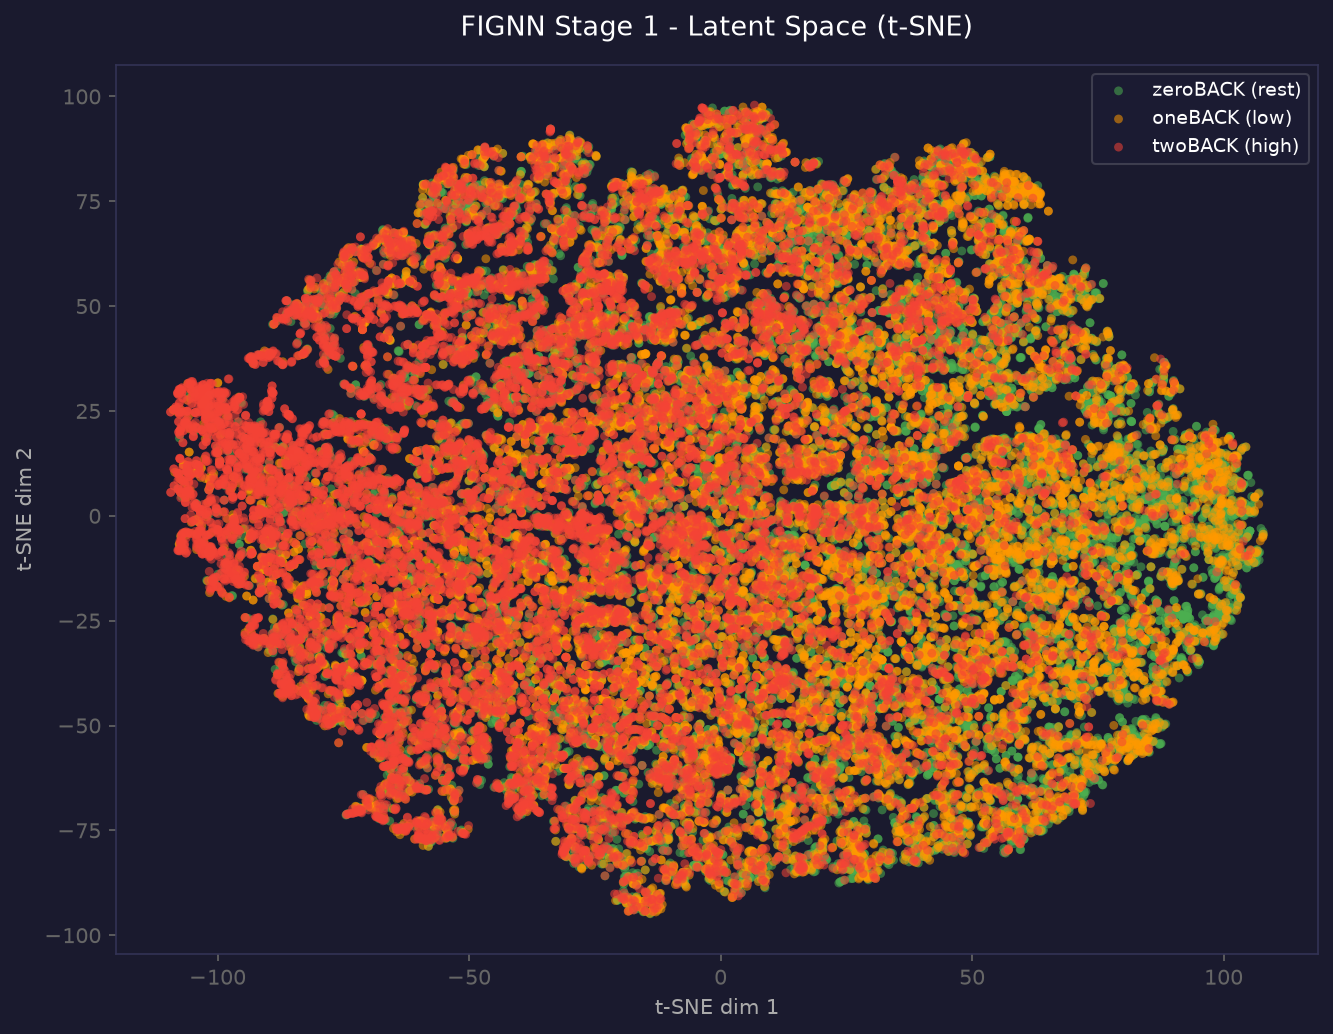

In [18]:
from IPython.display import Image, display
display(Image('/lp-dev/24BCE1793/outputs/plots/tsne_latent_space.png'))
# display(Image('/lp-dev/24BCE1793/outputs/plots/band_importance.png'))
# display(Image('/lp-dev/24BCE1793/outputs/plots/loss_curve.png'))

In [13]:
import pickle, torch

# Run this right now before you forget
from ...src.training.train import compute_dataset_stats
import pickle

with open('/lp-dev/24BCE1793/data/processed/all_graphs_29sub.pkl', 'rb') as f:
    graphs = pickle.load(f)

mean, std = compute_dataset_stats(graphs)
torch.save({'mean': mean, 'std': std}, 
           '/lp-dev/24BCE1793/outputs/checkpoints/normalisation_stats.pt')
print("Saved normalisation stats")

ImportError: attempted relative import with no known parent package

In [7]:
import mne
import os
import json
import scipy.io as sio
import numpy as np

mne.set_log_level('ERROR')

DATA_ROOT = "/lp-dev/24BCE1793/data/raw"

# ── 1. Check one subject from each group ─────────────────────────────
print("=" * 60)
print("CHANNEL STRUCTURE COMPARISON")
print("=" * 60)

for sub in ['sub-01', 'sub-10']:
    path = os.path.join(DATA_ROOT, sub, 'ses-S1', 'eeg', 'zeroBACK.set')
    raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
    ecg  = [c for c in raw.ch_names if 'ECG' in c.upper()]
    print(f"\n{sub}:")
    print(f"  Total channels : {len(raw.ch_names)}")
    print(f"  ECG channels   : {ecg}")
    print(f"  Has Cz         : {'Cz' in raw.ch_names}")
    print(f"  Sampling rate  : {raw.info['sfreq']} Hz")
    print(f"  Duration       : {raw.times[-1]:.1f}s")
    print(f"  Channel names  : {raw.ch_names}")

# ── 2. Check all 3 sessions for one subject ───────────────────────────
print("\n" + "=" * 60)
print("SESSION CONSISTENCY — sub-01")
print("=" * 60)

for ses in ['ses-S1', 'ses-S2', 'ses-S3']:
    for task in ['zeroBACK', 'oneBACK', 'twoBACK']:
        path = os.path.join(DATA_ROOT, 'sub-01', ses, 'eeg', f'{task}.set')
        raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
        print(f"  {ses} {task}: {len(raw.ch_names)} ch  {raw.times[-1]:.1f}s  {len(raw.annotations)} annotations")

# ── 3. Look at annotation/event codes ────────────────────────────────
print("\n" + "=" * 60)
print("EVENT CODES — sub-01 ses-S1 zeroBACK")
print("=" * 60)

path = os.path.join(DATA_ROOT, 'sub-01', 'ses-S1', 'eeg', 'zeroBACK.set')
raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
from collections import Counter
event_counts = Counter(raw.annotations.description)
for event, count in sorted(event_counts.items()):
    print(f"  {event:15s}: {count} occurrences")

# ── 4. Look at behavioral data ────────────────────────────────────────
print("\n" + "=" * 60)
print("BEHAVIORAL DATA — sub-01 ses-S1 0-Back")
print("=" * 60)

mat_path = os.path.join(DATA_ROOT, 'sub-01', 'ses-S1', 'behavioral', '0-Back.mat')
try:
    mat = sio.loadmat(mat_path)
    print(f"  Keys: {[k for k in mat.keys() if not k.startswith('_')]}")
    for k, v in mat.items():
        if not k.startswith('_'):
            print(f"  {k}: shape={np.array(v).shape}  dtype={np.array(v).dtype}")
except Exception as e:
    print(f"  Error: {e}")

# ── 5. Check chanlocs file ────────────────────────────────────────────
print("\n" + "=" * 60)
print("CHANLOCS — sub-01 ses-S1")
print("=" * 60)

chanlocs_path = os.path.join(DATA_ROOT, 'sub-01', 'ses-S1', 'chanlocs', 'get_chanlocs.txt')
with open(chanlocs_path) as f:
    content = f.read()
print(content[:500])

# ── 6. Cross-subject duration check ──────────────────────────────────
print("\n" + "=" * 60)
print("DURATION CONSISTENCY ACROSS SUBJECTS — zeroBACK ses-S1")
print("=" * 60)

for sub_n in range(1, 30):
    sub  = f"sub-{sub_n:02d}"
    path = os.path.join(DATA_ROOT, sub, 'ses-S1', 'eeg', 'zeroBACK.set')
    if not os.path.exists(path):
        print(f"  {sub}: FILE NOT FOUND")
        continue
    raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
    ecg = [c for c in raw.ch_names if 'ECG' in c.upper()]
    n_eeg = len(raw.ch_names) - len(ecg)
    print(f"  {sub}: {n_eeg} EEG  {raw.times[-1]:.1f}s  {raw.info['sfreq']}Hz")

CHANNEL STRUCTURE COMPARISON


/tmp/ipykernel_3627592/388242302.py:18: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:18: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:18: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:18: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=


sub-01:
  Total channels : 63
  ECG channels   : ['ECG1']
  Has Cz         : False
  Sampling rate  : 500.0 Hz
  Duration       : 396.6s
  Channel names  : ['Fp1', 'Fz', 'F3', 'F7', 'FT9', 'FC5', 'FC1', 'C3', 'T7', 'ECG1', 'CP5', 'CP1', 'Pz', 'P3', 'P7', 'O1', 'Oz', 'O2', 'P4', 'P8', 'TP10', 'CP6', 'CP2', 'FCz', 'C4', 'T8', 'FT10', 'FC6', 'FC2', 'F4', 'F8', 'Fp2', 'AF7', 'AF3', 'AFz', 'F1', 'F5', 'FT7', 'FC3', 'C1', 'C5', 'TP7', 'CP3', 'P1', 'P5', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'P6', 'P2', 'CPz', 'CP4', 'TP8', 'C6', 'C2', 'FC4', 'FT8', 'F6', 'AF8', 'AF4', 'F2']

sub-10:
  Total channels : 64
  ECG channels   : ['ECG1']
  Has Cz         : True
  Sampling rate  : 500.0 Hz
  Duration       : 344.9s
  Channel names  : ['Fp1', 'Fz', 'F3', 'F7', 'FT9', 'FC5', 'FC1', 'C3', 'T7', 'ECG1', 'CP5', 'CP1', 'Pz', 'P3', 'P7', 'O1', 'Oz', 'O2', 'P4', 'P8', 'TP10', 'CP6', 'CP2', 'FCz', 'C4', 'T8', 'FT10', 'FC6', 'FC2', 'F4', 'F8', 'Fp2', 'AF7', 'AF3', 'AFz', 'F1', 'F5', 'FT7', 'FC3', 'C1', 'C5', '

/tmp/ipykernel_3627592/388242302.py:36: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:36: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:36: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:36: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw  = mne.io.read_raw_eeglab(path, preload=False, verbose=

  ses-S1 zeroBACK: 63 ch  396.6s  203 annotations
  ses-S1 oneBACK: 63 ch  411.3s  198 annotations


...

/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=Fals

  sub-25: 63 EEG  331.9s  500.0Hz
  sub-26: 63 EEG  328.7s  500.0Hz


/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=Fals

  sub-27: 63 EEG  328.3s  500.0Hz
  sub-28: 63 EEG  331.9s  500.0Hz
  sub-29: 63 EEG  321.9s  500.0Hz


/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)
/tmp/ipykernel_3627592/388242302.py:87: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(path, preload=False, verbose=False)


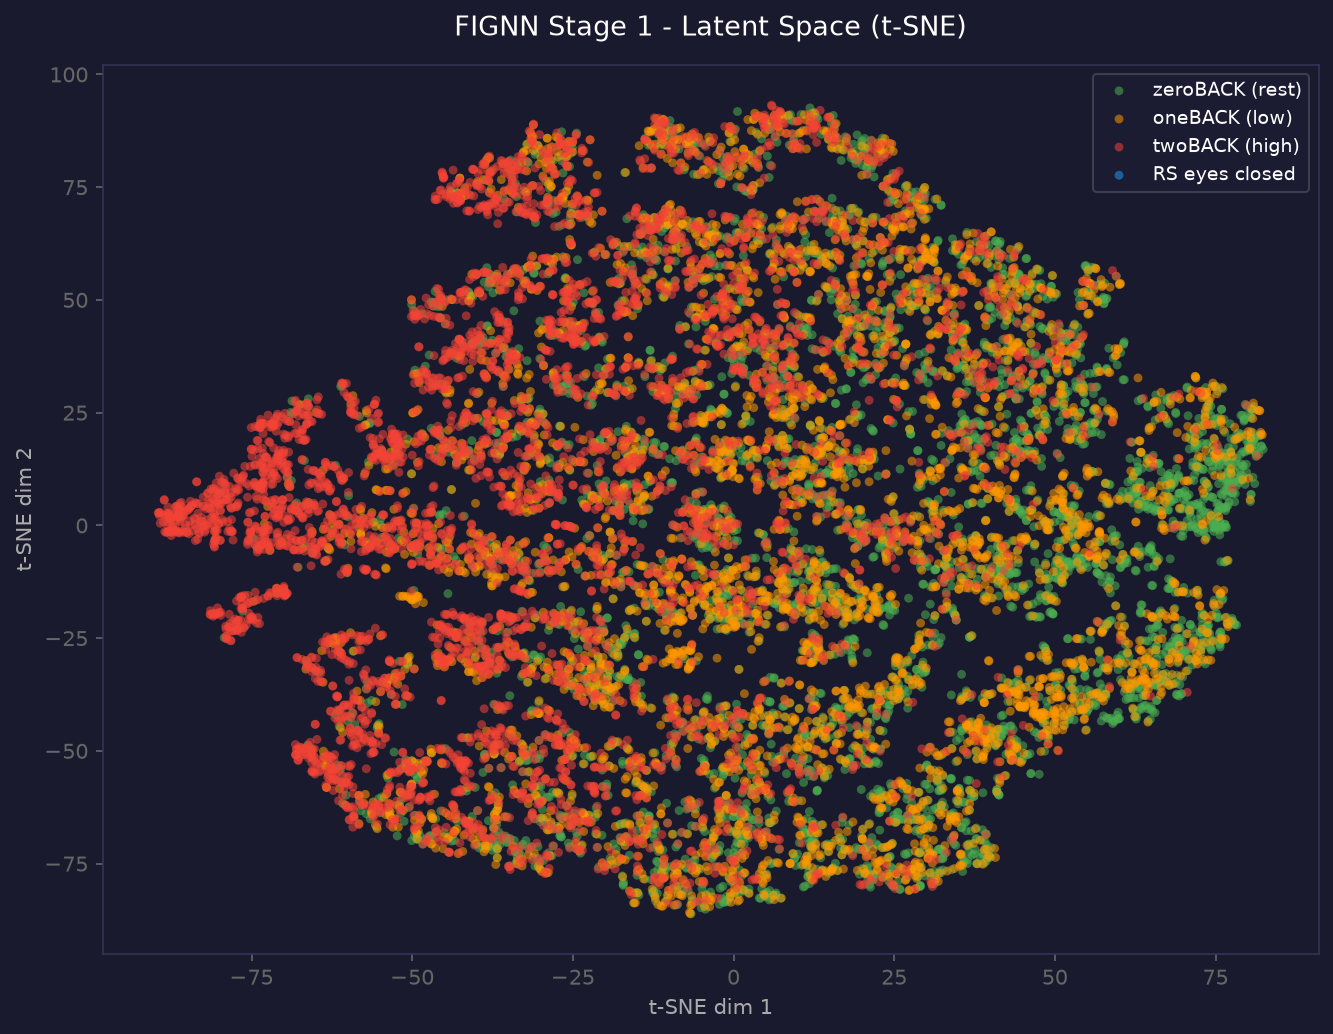

In [9]:
from IPython.display import Image
Image('/lp-dev/24BCE1793/outputs/plots/tsne_latent_space.png')